**CRAWLING**

In [ ]:
import subprocess
import sys

subprocess.run(["apt-get", "update", "-qq"], check=True)

subprocess.run(
    [
        "apt-get", "install", "-y",
        "libatk1.0-0",
        "libatk-bridge2.0-0",
        "libatspi2.0-0",
        "libxcomposite1",
        "libxdamage1",
        "libxfixes3",
        "libxrandr2",
        "libgbm1",
        "libasound2t64",
        "libnss3",
        "libnspr4",
        "libxshmfence1",
        "libx11-xcb1",
        "libxcb1",
        "libxext6",
        "libx11-6",
        "libxcb-dri3-0",
        "libdrm2",
        "libcups2",
        "libpango-1.0-0",
        "libcairo2",
        "libatspi2.0-0",
        "libgtk-3-0",
        "libglib2.0-0",
        "libdbus-1-3",
        "libexpat1",
        "libfontconfig1",
        "libfreetype6",
        "libxkbcommon0",
        "libwayland-client0",
        "libwayland-egl1",
        "libwayland-cursor0",
        "libwayland-server0"
    ],
    check=True
)

print("Instalasi dependensi selesai.")

Instalasi dependensi selesai.


In [ ]:
import getpass
import subprocess
import pandas as pd
from pathlib import Path

token = getpass.getpass("Twitter auth token: ").strip()

output_dir = Path("/content/tweets-data")
output_dir.mkdir(parents=True, exist_ok=True)

queries = {
    "pln": "PLN since:2025-10-11 until:2026-10-12",
    "listrik_padam": '"listrik padam" since:2025-10-11 until:2026-10-12',
    "token_listrik": '"token listrik" since:2025-10-11 until:2026-10-12'
}

dataframes = []

for name, query in queries.items():
    filename = f"{name}.csv"

    print(f"\nMengambil data: {name}")

    result = subprocess.run(
        [
            "npx", "-y", "tweet-harvest@2.7.1",
            "-o", filename,
            "-s", query,
            "--tab", "LATEST",
            "-l", "300",
            "--token", token
        ],
        cwd=str(output_dir),
        capture_output=True,
        text=True,
        timeout=1800
    )

    print(result.stdout[-2500:])

    if result.stderr:
        print("Pesan stderr:", result.stderr[-1000:])

    path = output_dir / filename

    if path.exists() and path.stat().st_size > 0:
        try:
            df = pd.read_csv(path)

            if not df.empty:
                df["keyword_source"] = name
                dataframes.append(df)
                print(f"Berhasil membaca {len(df)} tweet.")
            else:
                print("File ada, tetapi tidak berisi tweet.")

        except pd.errors.EmptyDataError:
            print("CSV kosong.")

    else:
        print("File tidak ditemukan.")

if dataframes:
    merged = pd.concat(dataframes, ignore_index=True)
    before = len(merged)

    if "id_str" in merged.columns:
        merged = merged.drop_duplicates(subset="id_str", keep="first")
    else:
        merged = merged.drop_duplicates()

    merged = merged.reset_index(drop=True)

    print(f"\nTotal sebelum hapus duplikat: {before}")
    print(f"Total setelah hapus duplikat: {len(merged)}")

    merged.to_csv(
        output_dir / "merged_raw.csv",
        index=False,
        encoding="utf-8-sig"
    )

    display(
        merged[
            ["created_at", "full_text", "lang", "keyword_source"]
        ].head(10)
    )

else:
    print("Belum ada data yang berhasil dikumpulkan.")

**CLEANING**

In [ ]:
import pandas as pd
import re
from pathlib import Path

input_path = Path("/content/tweets-data/merged_raw.csv")
df = pd.read_csv(input_path)

df["full_text"] = df["full_text"].fillna("").astype(str).str.strip()
df = df[df["full_text"] != ""]
df = df.drop_duplicates(subset="id_str", keep="first")

df["created_at"] = pd.to_datetime(
    df["created_at"], errors="coerce", utc=True
).dt.tz_convert("Asia/Jakarta")

start_date = pd.Timestamp("2025-10-11", tz="Asia/Jakarta")
end_date = pd.Timestamp("2026-10-12", tz="Asia/Jakarta")

df = df[
    (df["created_at"] >= start_date) &
    (df["created_at"] < end_date)
]

df["lang"] = df["lang"].fillna("").astype(str).str.lower()
df = df[df["lang"].isin(["in", "id"])]

pattern = (
    r"\b(pln|listrik|pemadaman|padam|mati lampu|token listrik|"
    r"listrik mati|gangguan listrik|listrik nyala|listrik hidup|"
    r"prabayar|pascabayar)\b"
)

df = df[
    df["full_text"].str.contains(pattern, case=False, regex=True, na=False)
]

def clean_text(text):
    text = text.lower()  # teks menjadi huruf kecil
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)  # hapus URL
    text = re.sub(r"@\w+", " ", text)  # hapus mention pengguna
    text = re.sub(r"#", "", text)  # hapus simbol hashtag tanpa hapus kata setelahnya
    text = re.sub(r"[^\w\s]", " ", text)  # hapus tanda baca dan karakter khusus
    text = re.sub(r"\s+", " ", text).strip()  # merapikan spasi berlebih
    return text

df["clean_text"] = df["full_text"].apply(clean_text)
df = df[df["clean_text"] != ""]

output_path = Path("/content/tweets-data/merged_clean.csv")
df.to_csv(output_path, index=False, encoding="utf-8-sig")

print("Jumlah data bersih:", len(df))
print("Rentang tanggal:", df["created_at"].min(), "sampai", df["created_at"].max())
print("Lokasi file:", output_path)

display(df[["created_at", "full_text", "clean_text", "lang"]].head(15))

In [ ]:

import pandas as pd
import re

# 1. Membaca file merged_clean
df = pd.read_csv('/content/sample_data/merged_clean.csv')

print("Jumlah data awal:", len(df))
print("Kolom awal:", df.columns.tolist())

# 2. Membersihkan emoji dan emotikon
def hapus_emoji_emotikon(teks):
    if pd.isna(teks):
        return teks

    teks = str(teks)

    # Menghapus emotikon berbasis karakter
    teks = re.sub(
        r'(?::|;|=|8|x|X|<|>)-?[)(DPp/\\]|'
        r'[:;=]-?[)(DPp/\\]|'
        r'\^[_\-]?\^|T_T|T\.T|-_-|\.M\.',
        ' ',
        teks
    )

    # Menghapus emoji Unicode
    pola_emoji = re.compile(
        "["
        "\U0001F1E6-\U0001F1FF"
        "\U0001F300-\U0001F5FF"
        "\U0001F600-\U0001F64F"
        "\U0001F680-\U0001F6FF"
        "\U0001F700-\U0001F77F"
        "\U0001F780-\U0001F7FF"
        "\U0001F800-\U0001F8FF"
        "\U0001F900-\U0001F9FF"
        "\U0001FA00-\U0001FAFF"
        "\U00002700-\U000027BF"
        "\U00002600-\U000026FF"
        "]+",
        flags=re.UNICODE
    )

    teks = pola_emoji.sub(' ', teks)

    # Merapikan spasi
    teks = re.sub(r'\s+', ' ', teks).strip()

    return teks

# Terapkan cleaning pada kolom clean_text
if 'clean_text' in df.columns:
    df['clean_text'] = df['clean_text'].apply(hapus_emoji_emotikon)
else:
    raise ValueError("Kolom clean_text tidak ditemukan.")

# 3. Menghapus kolom teks asli/raw
if 'full_text' in df.columns:
    df = df.drop(columns=['full_text'])

# 4. Menghapus duplikat berdasarkan teks hasil cleaning
jumlah_sebelum = len(df)

df = df.drop_duplicates(
    subset=['clean_text'],
    keep='first'
).reset_index(drop=True)

jumlah_sesudah = len(df)

# 5. Menyimpan file hasil
output_path = '/content/merged_clean_final.csv'
df.to_csv(output_path, index=False, encoding='utf-8-sig')

# 6. Menampilkan ringkasan hasil
print("\n=== HASIL CLEANING ===")
print("Data sebelum hapus duplikat:", jumlah_sebelum)
print("Duplikat dihapus:", jumlah_sebelum - jumlah_sesudah)
print("Jumlah data akhir:", jumlah_sesudah)
print("Kolom akhir:", df.columns.tolist())
print("File tersimpan:", output_path)

# 7. Mengunduh file hasil
from google.colab import files
files.download(output_path)

Jumlah data awal: 655
Kolom awal: ['conversation_id_str', 'created_at', 'favorite_count', 'full_text', 'id_str', 'image_url', 'in_reply_to_screen_name', 'lang', 'location', 'quote_count', 'reply_count', 'retweet_count', 'tweet_url', 'user_id_str', 'username', 'keyword_source', 'clean_text']

=== HASIL CLEANING ===
Data sebelum hapus duplikat: 655
Duplikat dihapus: 145
Jumlah data akhir: 510
Kolom akhir: ['conversation_id_str', 'created_at', 'favorite_count', 'id_str', 'image_url', 'in_reply_to_screen_name', 'lang', 'location', 'quote_count', 'reply_count', 'retweet_count', 'tweet_url', 'user_id_str', 'username', 'keyword_source', 'clean_text']
File tersimpan: /content/merged_clean_final.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files

files.download("/content/tweets-data/merged_clean.csv")

### **MENAMPILKAN 20 TWEET PERTAMA**

In [ ]:
import pandas as pd
df = pd.read_csv('merged_clean.csv')
print("20 TEKS TWEET PERTAMA ")
for i in range(20):
    print(f"Baris {i}: {df.loc[i, 'clean_text']}\n")

20 TEKS TWEET PERTAMA 
Baris 0: baik kak apabila demikian terima kasih update informasinya ya kak agar semua makin mudah ayo download aplikasi new pln mobile tks iqbal

Baris 1: baik kak apabila demikian terima kasih update informasinya ya kak agar semua makin mudah ayo download aplikasi new pln mobile tks iqbal

Baris 2: gk jadi min barusan tak coba lagi lwt aplikasi pln mobile udh bisa tp tetep masih kena omel ibu negara ini krn kelamaan br bisa beli

Baris 3: pertama kalinya up rembang menggelar kompetisi akselerasi kompetensi operator pada 6 21 oktober 2026 memeriahkan hut ke 31 pln nusantara power ajang ini mengasah kemampuan teknis dan kerja sama tim melalui simulator pembangkit powerasone uprembang

Baris 4: deals rp10 stok banyak 00 00 5 11 oktober 00 00 12 00 18 00 voucher pln 5rb stok 170 voucher alfamart 10rb stok 70 voucher hophop 20rb stok 50 klik vouchernya pas jamnya bisa delay on bbrpa detik

Baris 5: voucher deals rp1 5 11 okt 00 00 12 00 18 00 pln kuota 170 alfamart k

### **MEMBERI LABEL MANUAL**

In [ ]:
import pandas as pd
df = pd.read_csv('merged_clean.csv')
df['sentimen_asli'] = None

df.loc[0, 'sentimen_asli'] = 'netral'
df.loc[1, 'sentimen_asli'] = 'netral'
df.loc[2, 'sentimen_asli'] = 'negatif'
df.loc[3, 'sentimen_asli'] = 'netral'
df.loc[4, 'sentimen_asli'] = 'netral'
df.loc[5, 'sentimen_asli'] = 'netral'
df.loc[6, 'sentimen_asli'] = 'netral'
df.loc[7, 'sentimen_asli'] = 'netral'
df.loc[8, 'sentimen_asli'] = 'positif'
df.loc[9, 'sentimen_asli'] = 'netral'
df.loc[10, 'sentimen_asli'] = 'netral'
df.loc[11, 'sentimen_asli'] = 'negatif'
df.loc[12, 'sentimen_asli'] = 'netral'
df.loc[13, 'sentimen_asli'] = 'positif'
df.loc[14, 'sentimen_asli'] = 'netral'
df.loc[15, 'sentimen_asli'] = 'negatif'
df.loc[16, 'sentimen_asli'] = 'netral'
df.loc[17, 'sentimen_asli'] = 'positif'
df.loc[18, 'sentimen_asli'] = 'netral'
df.loc[19, 'sentimen_asli'] = 'negatif'

df.to_csv('merged_clean_sentimen.csv', index=False)
print("File berhasil diberi label")

File berhasil diberi label


### **ANALISIS SENTIMEN**

HASIL ANALISIS SENTIMEN TENTANG PLN (Menggunakan RoBERTa)


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]


1. Distribusi Kategori Sentimen:
   - Netral: 340 tweet (51.91%)
   - Positif: 222 tweet (33.89%)
   - Negatif: 93 tweet (14.20%)


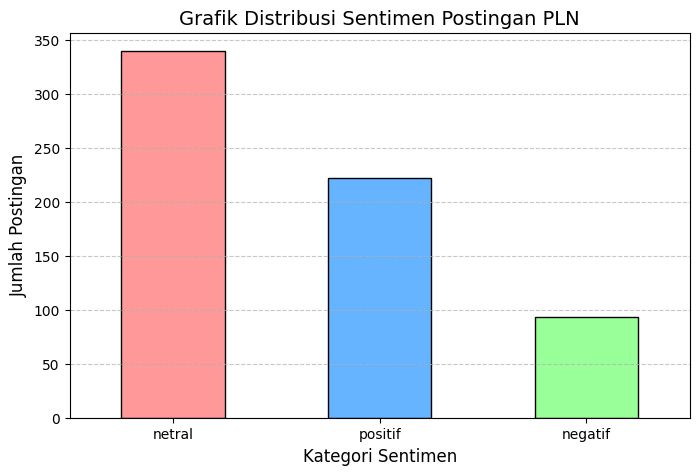


2. Tabel Hasil Klasifikasi (Sampel):
   clean_text                                                        Prediksi Sistem
   -------------------------------------------------------------------------------------
   baik kak apabila demikian terima kasih update informasinya y...   Netral
   baik kak apabila demikian terima kasih update informasinya y...   Netral
   gk jadi min barusan tak coba lagi lwt aplikasi pln mobile ud...   Negatif
   pertama kalinya up rembang menggelar kompetisi akselerasi ko...   Netral
   deals rp10 stok banyak 00 00 5 11 oktober 00 00 12 00 18 00 ...   Netral
   voucher deals rp1 5 11 okt 00 00 12 00 18 00 pln kuota 170 a...   Netral
   deals rp1 000 00 00 alfamart 10rb pln 5rb ultra voucher 10rb...   Netral
   halo kak dm kakak sudah admin respon ya pln menerapkan undan...   Netral
   ada yang sigap kasih aba aba ada yang paham saat laptop berm...   Positif
   kak abram estimasi waktu penormalan kurang lebih 3 jam namun...   Netral

3. Pemeriksaan Evaluasi (

/tmp/ipykernel_1666/3891788341.py:69: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_evaluasi['sesuai'] = df_evaluasi['sentimen_asli'].str.lower() == df_evaluasi['sentimen_prediksi']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from transformers import pipeline

df = pd.read_csv('merged_clean_sentimen.csv')

print("="*65)
print("HASIL ANALISIS SENTIMEN TENTANG PLN (Menggunakan RoBERTa)")
print("="*65)

nama_model = "w11wo/indonesian-roberta-base-sentiment-classifier"
nlp_sentimen = pipeline("sentiment-analysis", model=nama_model, tokenizer=nama_model)

def prediksi_sentimen_roberta(text):
    try:
        text = str(text)[:500]
        hasil = nlp_sentimen(text)
        label = hasil[0]['label'].lower()

        if label == 'positive':
            return 'positif'
        elif label == 'negative':
            return 'negatif'
        else:
            return 'netral'
    except:
        return 'netral'

df['sentimen_prediksi'] = df['clean_text'].apply(prediksi_sentimen_roberta)


#Jumlah dan Persentase Sentimen
jumlah_sentimen = df['sentimen_prediksi'].value_counts()
persen_sentimen = df['sentimen_prediksi'].value_counts(normalize=True) * 100

print("\n1. Distribusi Kategori Sentimen:")
for kategori in jumlah_sentimen.index:
    print(f"   - {kategori.capitalize()}: {jumlah_sentimen[kategori]} tweet ({persen_sentimen[kategori]:.2f}%)")


#Grafik Distribusi Sentimen
plt.figure(figsize=(8, 5))
warna = ['#ff9999', '#66b3ff', '#99ff99']
jumlah_sentimen.plot(kind='bar', color=warna, edgecolor='black')
plt.title('Grafik Distribusi Sentimen Postingan PLN', fontsize=14)
plt.xlabel('Kategori Sentimen', fontsize=12)
plt.ylabel('Jumlah Postingan', fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


#Tabel Teks Postingan dan Hasil
print("\n2. Tabel Hasil Klasifikasi (Sampel):")
print(f"   {'clean_text':<65} Prediksi Sistem")
print("   " + "-"*85)
for _, row in df.head(10).iterrows():
    teks = str(row['clean_text']).replace('\n', ' ')
    teks = teks[:60] + '...' if len(teks) > 60 else teks
    print(f"   {teks:<65} {row['sentimen_prediksi'].capitalize()}")


# Pemeriksaan Manual vs Sistem
if 'sentimen_asli' in df.columns:
    df_evaluasi = df.dropna(subset=['sentimen_asli'])

    if not df_evaluasi.empty:
        print("\n3. Pemeriksaan Evaluasi (Manual vs Prediksi Sistem):")
        df_evaluasi['sesuai'] = df_evaluasi['sentimen_asli'].str.lower() == df_evaluasi['sentimen_prediksi']
        jumlah_sesuai = df_evaluasi['sesuai'].sum()
        persen_sesuai = (jumlah_sesuai / len(df_evaluasi)) * 100
        print(f"   Jumlah Kesesuaian: {jumlah_sesuai} dari {len(df_evaluasi)} sampel evaluasi ({persen_sesuai:.2f}%)")

        tidak_sesuai = df_evaluasi[~df_evaluasi['sesuai']]
        if not tidak_sesuai.empty:
            print("\n   Contoh Analisis Ketidaksesuaian:")
            for idx, row in tidak_sesuai.head(3).iterrows():
                print(f"   - Teks     : {row['clean_text']}")
                print(f"     Labelmu  : {row['sentimen_asli']}")
                print(f"     Sistem   : {row['sentimen_prediksi']}")
                print("     Bahas    : Model AI mungkin menangkap konteks kalimat secara keseluruhan yang berbeda dari perspektif manusia, atau gagal memahami ironi/sarkasme khusus.")
                print("")
    else:
         print("\n3. Pemeriksaan Evaluasi: Kolom 'sentimen_asli' ditemukan, tetapi tidak ada baris yang diisi.")
else:
    print("\n3. Pemeriksaan Evaluasi: Lewati. Kolom 'sentimen_asli' belum dibuat di file CSV.")

if 'favorite_count' in df.columns:
    df = df.rename(columns={'favorite_count': 'like_count'})

df.to_csv('merged_clean_sentimen_lengkap.csv', index=False)
from google.colab import files
files.download('merged_clean_sentimen_lengkap.csv')

## Clustering

In [1]:
import joblib
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

nltk.download("stopwords")

df = pd.read_csv("merged_clean_final.csv")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [2]:
stop = set(stopwords.words("indonesian")) | set(stopwords.words("english"))

# kata gaul, dan kata yang ada di hampir semua postingan
stop |= {"pln", "listrik", "yg", "ga", "gak", "nya", "aja", "banget", "udah", "sih", "nih"}

stop = list(stop)

In [3]:
vectorizer = TfidfVectorizer(stop_words=stop, min_df=2, max_df=0.9)
X = vectorizer.fit_transform(df["clean_text"])

print(X.shape)

(510, 636)


/usr/local/lib/python3.13/dist-packages/sklearn/feature_extraction/text.py:402: UserWarning: Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['baiknya', 'berkali', 'kali', 'kurangnya', 'mata', 'olah', 'sekurang', 'setidak', 'tama', 'tidaknya'] not in stop_words.
  warnings.warn(


In [4]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
df["cluster"] = kmeans.fit_predict(X)

print(df["cluster"].value_counts().sort_index())

cluster
0    194
1    240
2     76
Name: count, dtype: int64


In [6]:
kata = vectorizer.get_feature_names_out()
urutan = kmeans.cluster_centers_.argsort()[:, ::-1]

ringkasan = {}
for k in range(3):
    data_k = df[df["cluster"] == k]
    kata_dominan = [kata[i] for i in urutan[k, :5]]
    contoh = data_k["clean_text"].sample(min(3, len(data_k)), random_state=42).tolist()

    ringkasan[k] = {"ukuran": len(data_k), "kata_dominan": kata_dominan, "contoh": contoh}

    print(f"Cluster {k} ({len(data_k)} postingan)")
    print("Lima kata dominan:", kata_dominan)
    for c in contoh:
        print("  -", c[:150])
    print()

Cluster 0 (194 postingan)
Lima kata dominan: ['padam', 'jam', 'token', 'ya', 'mati']
  - kenal sama tetangga kos gara gara listrik padam
  - gak tahu knp besok mau call pln deh
  - sebel bgt ama bunyi token listrik anying punya tetangga kos udh 2 hari bunyi kagak diisi isi

Cluster 1 (240 postingan)
Lima kata dominan: ['token', 'gopay', 'pln50rbcuma40rb', '40rb', '50rb']
  - daripada nyesel kelewat promo mending beli token listrik sekarang di gopay app beli yang 50rb cuma bayar 40rb aja udah dapet biaya admin gratis promon
  - lagi ada promo token listrik di aplikasi gopay token 50rb jadi cuma 40rb udh termasuk biaya admin gess ini aku beli langsung karena promonya cuma samp
  - yang biasanya beli token listrik lewat aplikasi jangan lupa cek penawaran di gopay dulu ada promo token pln 50rb bayar 40rb aja dengan biaya admin gra

Cluster 2 (76 postingan)
Lima kata dominan: ['mohon', 'mimin', 'terkait', 'maaf', 'permasalahan']
  - hai kak atas ketidaknyamanannya mimin mohon maaf terkait p

Silhouette score: 0.094


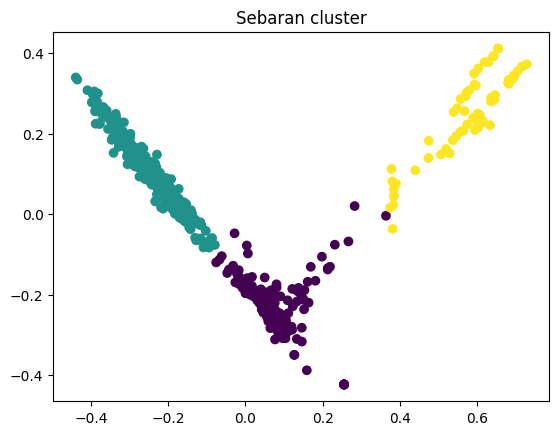

In [7]:
skor = silhouette_score(X, df["cluster"])
print("Silhouette score:", round(skor, 3))

koord = PCA(n_components=2, random_state=42).fit_transform(X.toarray())
plt.scatter(koord[:, 0], koord[:, 1], c=df["cluster"])
plt.title("Sebaran cluster")
plt.show()

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from wordcloud import WordCloud

kata = vectorizer.get_feature_names_out()
pusat = kmeans.cluster_centers_

In [9]:
frekuensi = {}
for k in range(3):
    lain = np.delete(pusat, k, axis=0).mean(axis=0)
    skor = np.clip(pusat[k] - lain, 0, None)
    frekuensi[k] = {kata[i]: float(skor[i]) for i in np.nonzero(skor)[0]}

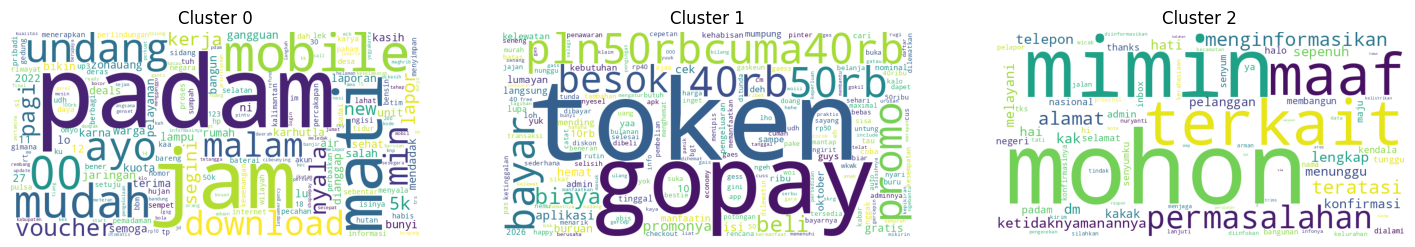

In [10]:
wc = {}
for k in range(3):
    wc[k] = WordCloud(background_color="white", width=800, height=400)
    wc[k] = wc[k].generate_from_frequencies(frekuensi[k])

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for k in range(3):
    axes[k].imshow(wc[k])
    axes[k].axis("off")
    axes[k].set_title(f"Cluster {k}")
plt.show()

In [11]:
nama_tema = {}
for k in range(3):
    terbesar = sorted(wc[k].words_.items(), key=lambda x: -x[1])[:3]
    nama_tema[k] = "Tema: " + ", ".join(kata_ for kata_, _ in terbesar)
    ringkasan[k]["nama_tema"] = nama_tema[k]

df["nama_tema"] = df["cluster"].map(nama_tema)

for k in range(3):
    jumlah = (df["cluster"] == k).sum()
    print(f"Cluster {k} | {jumlah} postingan | {nama_tema[k]}")

Cluster 0 | 194 postingan | Tema: padam, jam, mati
Cluster 1 | 240 postingan | Tema: token, gopay, pln50rbcuma40rb
Cluster 2 | 76 postingan | Tema: mohon, mimin, terkait


In [12]:
df.to_csv(
    "clustering_result.csv",
    index=False,
    encoding="utf-8-sig"
)

print("File clustering_result.csv berhasil disimpan.")

File clustering_result.csv berhasil disimpan.


In [13]:
from google.colab import files

files.download("clustering_result.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**REGRESI LINEAR**

UKURAN DATASET AWAL
Jumlah baris: 655
Jumlah kolom: 17

DATA SETELAH VALIDASI
Jumlah data valid: 655

CONTOH PERHITUNGAN FITUR


,full_text,jumlah_kata,jumlah_hashtag,favorite_count
0,"@furyfuko @furyfuko Baik Kak, apabila demikia...",24,0,0
1,"@jkbrams @jkbrams Baik Kak, apabila demikian ...",24,0,0
2,"@pln_123 gk jadi min, barusan tak coba lagi lw...",27,0,0
3,Pertama kalinya! ⚡ UP Rembang menggelar Kompet...,35,2,0
4,Deals Rp10 Stok banyak ⏱️00:00\n\n🗓️5 - 11 Okt...,43,0,2



PEMBAGIAN DATA
Data training: 524
Data testing: 131

MODEL REGRESI LINEAR
Intercept: 6.4598
Koefisien jumlah kata: -0.1488
Koefisien jumlah hashtag: -0.2534

EVALUASI MODEL
MAE: 1.7651
R²: -8.505

INTERPRETASI
MAE 1.7651 berarti rata-rata selisih absolut prediksi dan likes aktual sekitar 1.7651 likes.
R² sebesar -8.5050 bernilai negatif. Model lebih buruk daripada model pembanding yang memprediksi rata-rata likes data uji.

MODEL BERHASIL DISIMPAN
File: regression_model.joblib

HASIL PREDIKSI BERHASIL DISIMPAN
File: regression_predictions.csv

CONTOH HASIL PREDIKSI


,jumlah_kata,jumlah_hashtag,actual_likes,predicted_likes
333,36,0,0,1.103933
78,7,0,0,5.418362
503,30,1,0,1.743205
290,39,0,0,0.657613
360,34,0,0,1.401480
651,34,1,0,1.148111
55,7,0,0,5.418362
69,35,0,0,1.252707
155,7,0,2,5.418362
54,43,0,0,0.062519


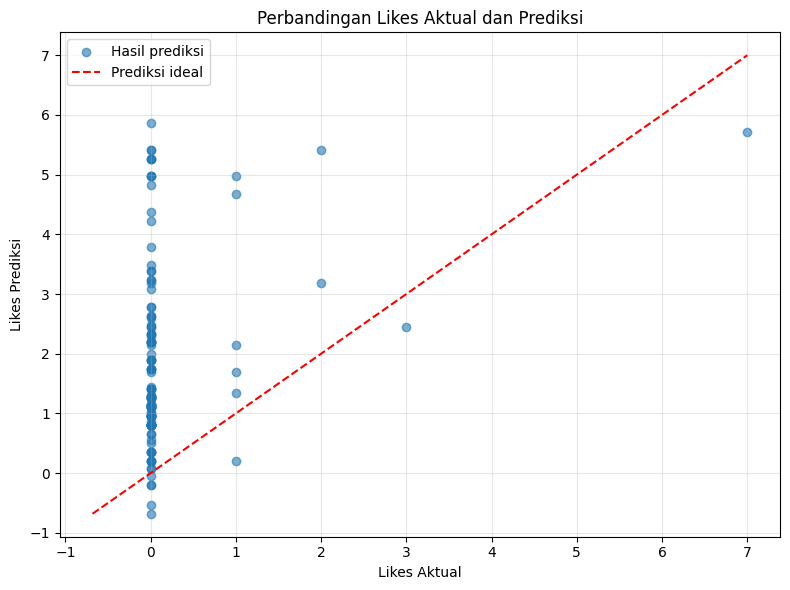


FORM PREDIKSI LIKES


IntText(value=20, description='Jumlah kata:', style=DescriptionStyle(description_width='initial'))

IntText(value=2, description='Jumlah hashtag:', style=DescriptionStyle(description_width='initial'))

Button(button_style='primary', description='Prediksi Likes', style=ButtonStyle())

Output()


KETERBATASAN MODEL
Model hanya menggunakan jumlah kata dan hashtag. Likes juga dipengaruhi usia postingan, jangkauan akun, isi pesan, dan faktor lainnya.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import ipywidgets as widgets
import joblib

from IPython.display import display, clear_output
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

# 1. Membaca dataset
file_path = '/content/sample_data/merged_clean.csv'
df = pd.read_csv(file_path)

print("UKURAN DATASET AWAL")
print("Jumlah baris:", len(df))
print("Jumlah kolom:", len(df.columns))

# 2. Memastikan kolom tersedia
kolom_wajib = ['full_text', 'favorite_count']

for kolom in kolom_wajib:
    if kolom not in df.columns:
        raise ValueError(
            f"Kolom '{kolom}' tidak ditemukan dalam dataset."
        )

# 3. Membersihkan data yang tidak valid
# Teks asli dan target harus tersedia
df = df.dropna(
    subset=['full_text', 'favorite_count']
).copy()

# Mengubah target menjadi numerik
df['favorite_count'] = pd.to_numeric(
    df['favorite_count'],
    errors='coerce'
)

# Menghapus target kosong, nonangka, dan negatif
df = df.dropna(subset=['favorite_count'])
df = df[df['favorite_count'] >= 0].copy()

# Menghapus teks kosong
df = df[
    df['full_text'].astype(str).str.strip() != ''
].copy()

print("\nDATA SETELAH VALIDASI")
print("Jumlah data valid:", len(df))

# 4. Menghitung fitur dari TEKS ASLI
df['jumlah_kata'] = df['full_text'].apply(
    lambda teks: len(str(teks).split())
)

df['jumlah_hashtag'] = df['full_text'].apply(
    lambda teks: len(
        re.findall(r'(?<!\w)#\w+', str(teks))
    )
)

print("\nCONTOH PERHITUNGAN FITUR")
display(
    df[
        ['full_text', 'jumlah_kata',
         'jumlah_hashtag', 'favorite_count']
    ].head()
)

# 5. Menentukan fitur dan target
X = df[['jumlah_kata', 'jumlah_hashtag']]
y = df['favorite_count']

# 6. Membagi data 80% training dan 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("\nPEMBAGIAN DATA")
print("Data training:", len(X_train))
print("Data testing:", len(X_test))

# 7. Melatih model hanya dengan data training
model = LinearRegression()
model.fit(X_train, y_train)

print("\nMODEL REGRESI LINEAR")
print("Intercept:", round(model.intercept_, 4))
print("Koefisien jumlah kata:", round(model.coef_[0], 4))
print("Koefisien jumlah hashtag:", round(model.coef_[1], 4))

# 8. Memprediksi data testing
y_pred = model.predict(X_test)

# 9. Evaluasi menggunakan MAE dan R²
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\nEVALUASI MODEL")
print("MAE:", round(mae, 4))
print("R²:", round(r2, 4))

print("\nINTERPRETASI")
print(
    f"MAE {mae:.4f} berarti rata-rata selisih absolut "
    f"prediksi dan likes aktual sekitar {mae:.4f} likes."
)

if r2 >= 0:
    print(
        f"R² sebesar {r2:.4f} menunjukkan proporsi variasi "
        "target yang dapat dijelaskan model pada data uji."
    )
else:
    print(
        f"R² sebesar {r2:.4f} bernilai negatif. "
        "Model lebih buruk daripada model pembanding "
        "yang memprediksi rata-rata likes data uji."
    )

# 10. Menyimpan model regresi
joblib.dump(model, 'regression_model.joblib')

print("\nMODEL BERHASIL DISIMPAN")
print("File: regression_model.joblib")

# 11. Menyimpan hasil prediksi ke CSV
prediction_result = X_test.copy()

prediction_result['actual_likes'] = y_test.values
prediction_result['predicted_likes'] = y_pred

prediction_result.to_csv(
    'regression_predictions.csv',
    index=False,
    encoding='utf-8-sig'
)

print("\nHASIL PREDIKSI BERHASIL DISIMPAN")
print("File: regression_predictions.csv")

print("\nCONTOH HASIL PREDIKSI")
display(prediction_result.head(10))

# 12. Grafik likes aktual dibandingkan prediksi
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.6,
    label='Hasil prediksi'
)

nilai_min = min(y_test.min(), y_pred.min())
nilai_max = max(y_test.max(), y_pred.max())

plt.plot(
    [nilai_min, nilai_max],
    [nilai_min, nilai_max],
    'r--',
    label='Prediksi ideal'
)

plt.xlabel('Likes Aktual')
plt.ylabel('Likes Prediksi')
plt.title('Perbandingan Likes Aktual dan Prediksi')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 13. Form interaktif prediksi likes
input_kata = widgets.IntText(
    value=20,
    description='Jumlah kata:',
    style={'description_width': 'initial'}
)

input_hashtag = widgets.IntText(
    value=2,
    description='Jumlah hashtag:',
    style={'description_width': 'initial'}
)

tombol = widgets.Button(
    description='Prediksi Likes',
    button_style='primary'
)

hasil = widgets.Output()

def prediksi_likes(b):
    with hasil:
        clear_output(wait=True)

        if input_kata.value < 0 or input_hashtag.value < 0:
            print(
                "Jumlah kata dan hashtag tidak boleh negatif."
            )
            return

        data_baru = pd.DataFrame({
            'jumlah_kata': [input_kata.value],
            'jumlah_hashtag': [input_hashtag.value]
        })

        prediksi = model.predict(data_baru)[0]

        print("HASIL PREDIKSI")
        print("Jumlah kata:", input_kata.value)
        print("Jumlah hashtag:", input_hashtag.value)
        print("Estimasi likes:", round(prediksi, 2))

        if prediksi < 0:
            print(
                "Catatan: estimasi negatif tidak bermakna "
                "sebagai jumlah likes sebenarnya dan "
                "menunjukkan keterbatasan model."
            )
        else:
            print(
                "Catatan: hasil merupakan estimasi model, "
                "bukan jumlah likes yang pasti."
            )

tombol.on_click(prediksi_likes)

print("\nFORM PREDIKSI LIKES")
display(input_kata, input_hashtag, tombol, hasil)

# 14. Keterbatasan model
print("\nKETERBATASAN MODEL")
print(
    "Model hanya menggunakan jumlah kata dan hashtag. "
    "Likes juga dipengaruhi usia postingan, jangkauan akun, "
    "isi pesan, dan faktor lainnya."
)

# 15. Mengunduh kedua file hasil
from google.colab import files

files.download('regression_model.joblib')
files.download('regression_predictions.csv')